<a href="https://colab.research.google.com/github/Quant-Siam/Quant-Siam/blob/main/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [344]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


# load dataset


In [345]:
df=pd.read_csv('/content/drive/MyDrive/Data Science Project/Dataset/MELBOURNE_HOUSE_PRICES_LESS.csv')

# Perform EDA

In [346]:
df.sample(8)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
4214,Moorabbin,19 Hamer St,3,h,1000000.0,S,O'Brien,3/09/2016,3189,Southern Metropolitan,2555,14.3,Kingston City Council
10870,Newport,3/49 Challis St,2,u,550000.0,PI,Sweeney,7/04/2018,3015,Western Metropolitan,5498,6.2,Hobsons Bay City Council
15057,Oakleigh South,4/1248 North Rd,4,u,774000.0,S,HAR,8/07/2017,3167,South-Eastern Metropolitan,3692,15.5,Kingston City Council
37124,Glenroy,1/43 Lytton St,4,t,745000.0,SP,Barry,18/11/2017,3046,Northern Metropolitan,8870,11.2,Moreland City Council
52596,Burwood,11 Fulton Cr,4,h,NaN,S,Buxton,26/05/2018,3125,Southern Metropolitan,5678,10.4,Monash City Council
11313,Hawthorn,11/284 Barkers Rd,2,u,NaN,S,Kay,7/05/2016,3122,Southern Metropolitan,11308,5.3,Boroondara City Council
14576,Preston,53 William St,3,h,917500.0,S,Nelson,8/04/2017,3072,Northern Metropolitan,14577,8.4,Darebin City Council
16969,Parkdale,6/25 White St,2,t,625500.0,S,Buxton,9/09/2017,3195,South-Eastern Metropolitan,5087,21.5,Kingston City Council


In [347]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63023 entries, 0 to 63022
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         63023 non-null  object 
 1   Address        63023 non-null  object 
 2   Rooms          63023 non-null  int64  
 3   Type           63023 non-null  object 
 4   Price          48433 non-null  float64
 5   Method         63023 non-null  object 
 6   SellerG        63023 non-null  object 
 7   Date           63023 non-null  object 
 8   Postcode       63023 non-null  int64  
 9   Regionname     63023 non-null  object 
 10  Propertycount  63023 non-null  int64  
 11  Distance       63023 non-null  float64
 12  CouncilArea    63023 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 6.3+ MB


In [349]:
df['Date']=pd.to_datetime(df['Date'],format="%d/%m/%Y")

In [350]:
df.sample(5)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63023 entries, 0 to 63022
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         63023 non-null  object        
 1   Address        63023 non-null  object        
 2   Rooms          63023 non-null  int64         
 3   Type           63023 non-null  object        
 4   Price          48433 non-null  float64       
 5   Method         63023 non-null  object        
 6   SellerG        63023 non-null  object        
 7   Date           63023 non-null  datetime64[ns]
 8   Postcode       63023 non-null  int64         
 9   Regionname     63023 non-null  object        
 10  Propertycount  63023 non-null  int64         
 11  Distance       63023 non-null  float64       
 12  CouncilArea    63023 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(7)
memory usage: 6.3+ MB


# Null and duplicated check

In [351]:
df.isnull().sum()/df.shape[0]

,0
Suburb,0.000000
Address,0.000000
Rooms,0.000000
Type,0.000000
Price,0.231503
Method,0.000000
SellerG,0.000000
Date,0.000000
Postcode,0.000000
Regionname,0.000000


In [352]:
df.duplicated().sum()
print('Here\'s  2 duplicated row . so drop these duplicated rows')
df.drop_duplicates(inplace=True)
print('Yeah, Duplicated rows has been gone')

Here's  2 duplicated row . so drop these duplicated rows
Yeah, Duplicated rows has been gone


In [353]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 63021 entries, 0 to 63022
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         63021 non-null  object        
 1   Address        63021 non-null  object        
 2   Rooms          63021 non-null  int64         
 3   Type           63021 non-null  object        
 4   Price          48432 non-null  float64       
 5   Method         63021 non-null  object        
 6   SellerG        63021 non-null  object        
 7   Date           63021 non-null  datetime64[ns]
 8   Postcode       63021 non-null  int64         
 9   Regionname     63021 non-null  object        
 10  Propertycount  63021 non-null  int64         
 11  Distance       63021 non-null  float64       
 12  CouncilArea    63021 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(7)
memory usage: 6.7+ MB


In [354]:
num_df=df.select_dtypes(include=['int','float'])
cat_df=df.select_dtypes(include=['object'])

In [355]:
num_df.sample(5),cat_df.sample(5)

(       Rooms     Price  Postcode  Propertycount  Distance
 47180      3  740000.0      3059           4864      20.4
 5903       4       NaN      3143           4836       6.3
 61686      2  641000.0      3041           3284       8.2
 58662      5       NaN      3150          15321      16.7
 11974      2  361000.0      3012           5058       6.4,
                Suburb          Address Type Method  SellerG  \
 20819       Reservoir     60 Powell St    h     VB   Nelson   
 24147  Mount Waverley      10 Wilga St    h     PI  McGrath   
 56984       Northcote  9/141 Clarke St    u      S   Nelson   
 43490       Mill Park    45 Hinkler Dr    h      S      Ray   
 14382         Ivanhoe   39 Thoresby Gr    h      S    Miles   
 
                   Regionname              CouncilArea  
 20819  Northern Metropolitan     Darebin City Council  
 24147   Eastern Metropolitan      Monash City Council  
 56984  Northern Metropolitan     Darebin City Council  
 43490  Northern Metropolitan  

# Perform univariate analysis on the categorical data in cat_df

Suburb 

Number of uniuqe value  380
Top largest 30 value_Counts Suburb
Reservoir         1241
Bentleigh East     845
Mount Waverley     831
Richmond           822
Glen Waverley      819
Craigieburn        783
Preston            699
Kew                668
Glen Iris          662
Brunswick          644
Northcote          613
South Yarra        603
Brighton           602
Hawthorn           601
Balwyn North       595
Name: count, dtype: int64
Rare value  Suburb
croydon             1
Warneet             1
Menzies Creek       1
Belgrave Heights    1
Maddingley          1
Yarrambat           1
viewbank            1
Kallista            1
Don Valley          1
Hopetoun Park       1
Toolern Vale        1
Wildwood            1
Avonsleigh          1
Castella            1
Kalorama            1
Name: count, dtype: int64



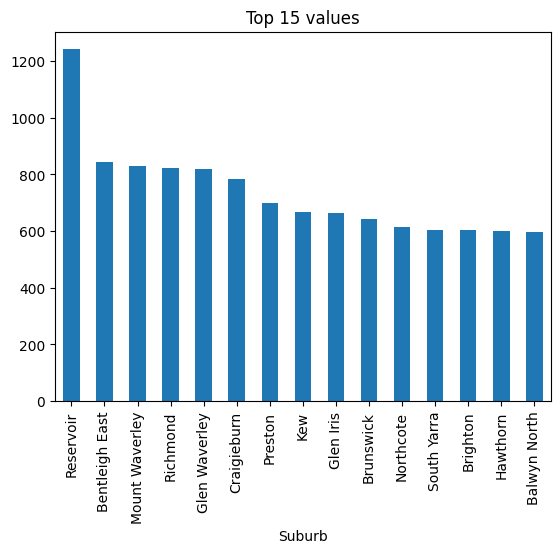

----------------------------------------
Address 

Number of uniuqe value  57754
Top largest 30 value_Counts Address
14 Moray St            7
3 Parker St            7
14 Northcote St        7
3 Donald St            7
57 Bay Rd              7
56 Victoria St         7
52 Station St          7
5 Charles St           7
2 Grout St             6
12/1 Glen Huntly Rd    6
2A Charles St          6
37 Cutter St           6
4 Maldon Ct            6
10 Mason Ct            6
39 York St             6
Name: count, dtype: int64
Rare value  Address
48 Golf Rd                1
407/132 Smith St          1
100 Sackville St          1
48 Webb St                1
1/44 Victoria St          1
8 Julius St               1
17/78 Oxford St           1
11 Abbott Ct              1
45 Worthing Av            1
41 Garden Rd              1
15 Sunlander Wy           1
3 Pittosporum Gr          1
24 Castle St              1
35 Glenard Dr             1
2/161 Wellington Pde S    1
Name: count, dtype: int64



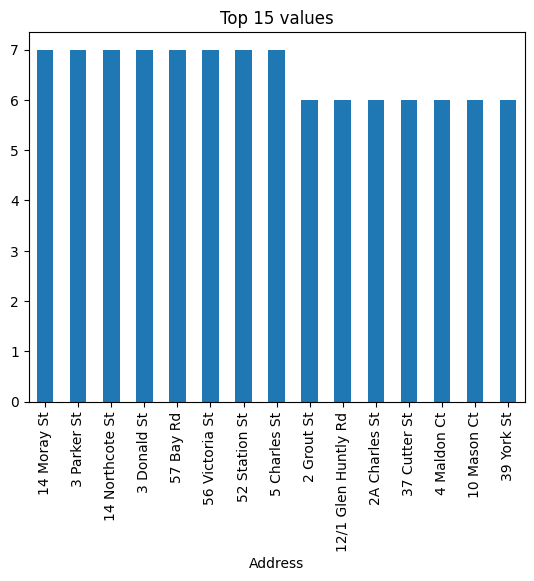

----------------------------------------
Type 

Number of uniuqe value  3
Top largest 30 value_Counts Type
h    45052
u    11655
t     6314
Name: count, dtype: int64
Rare value  Type
t     6314
u    11655
h    45052
Name: count, dtype: int64



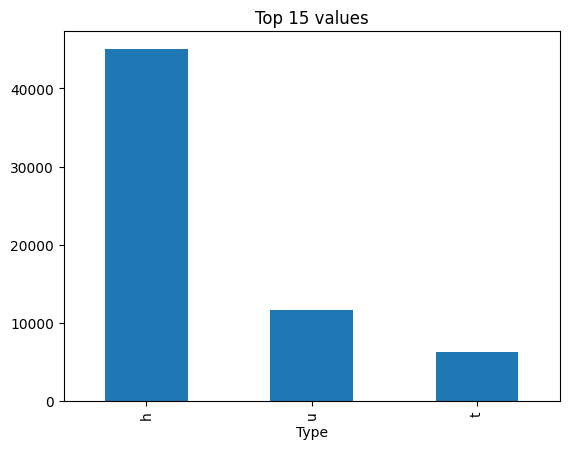

----------------------------------------
Method 

Number of uniuqe value  9
Top largest 30 value_Counts Method
S     34063
PI     9790
SP     8914
VB     5956
SN     2674
PN      651
W       484
SA      416
SS       73
Name: count, dtype: int64
Rare value  Method
SS       73
SA      416
W       484
PN      651
SN     2674
VB     5956
SP     8914
PI     9790
S     34063
Name: count, dtype: int64



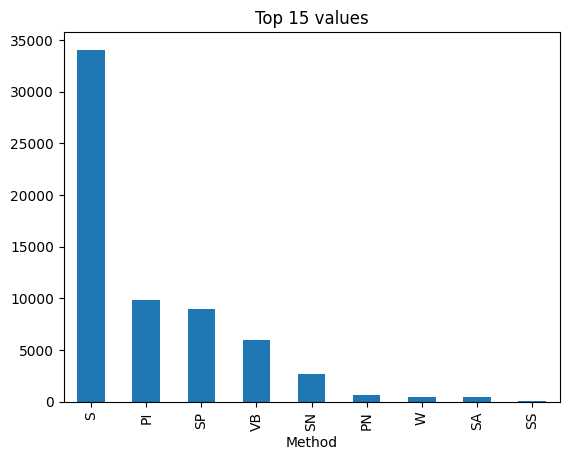

----------------------------------------
SellerG 

Number of uniuqe value  476
Top largest 30 value_Counts SellerG
Barry            6894
Jellis           5498
Nelson           4739
Ray              4554
hockingstuart    4332
Buxton           3357
Marshall         2844
Fletchers        1612
Biggin           1535
Harcourts        1211
Woodards         1183
YPA              1094
McGrath          1077
Noel             1064
Brad             1055
Name: count, dtype: int64
Rare value  SellerG
Integrity               1
Private/Tiernan's       1
For                     1
Hodges/Buxton           1
Enrich                  1
VicHomes                1
Upper                   1
Full                    1
Tanner                  1
Ausin                   1
North                   1
iProperty               1
Blue                    1
Len                     1
hockingstuart/Cayzer    1
Name: count, dtype: int64



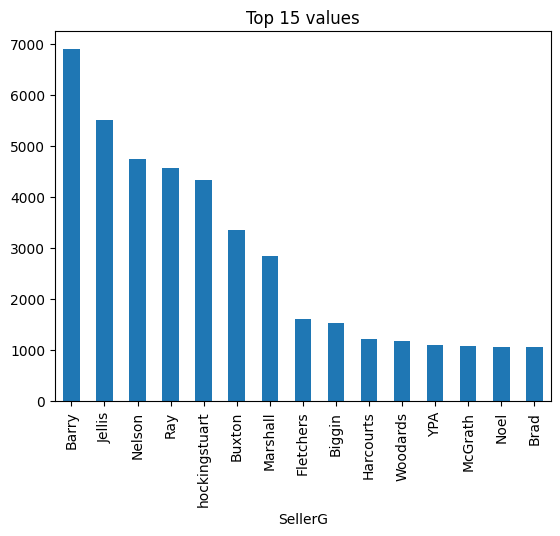

----------------------------------------
Regionname 

Number of uniuqe value  8
Top largest 30 value_Counts Regionname
Southern Metropolitan         17559
Northern Metropolitan         16780
Western Metropolitan          11717
Eastern Metropolitan          10395
South-Eastern Metropolitan     5212
Eastern Victoria                564
Northern Victoria               556
Western Victoria                238
Name: count, dtype: int64
Rare value  Regionname
Western Victoria                238
Northern Victoria               556
Eastern Victoria                564
South-Eastern Metropolitan     5212
Eastern Metropolitan          10395
Western Metropolitan          11717
Northern Metropolitan         16780
Southern Metropolitan         17559
Name: count, dtype: int64



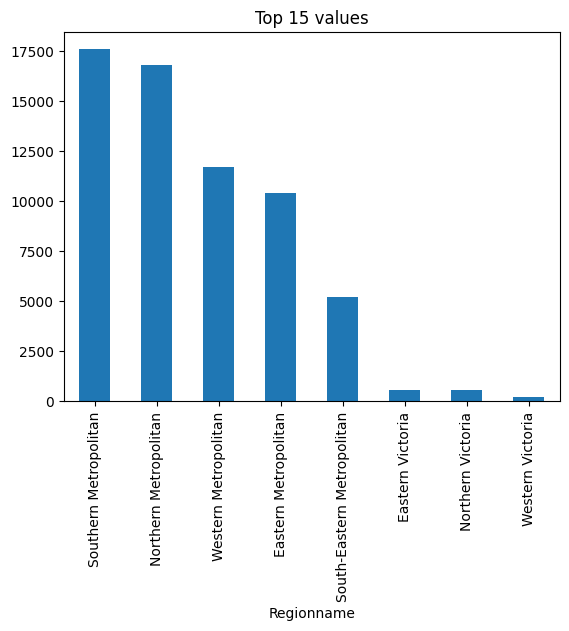

----------------------------------------
CouncilArea 

Number of uniuqe value  34
Top largest 30 value_Counts CouncilArea
Boroondara City Council       5132
Darebin City Council          4182
Banyule City Council          3656
Monash City Council           3592
Bayside City Council          3331
Brimbank City Council         3296
Moreland City Council         3029
Hume City Council             2939
Glen Eira City Council        2934
Melbourne City Council        2728
Whittlesea City Council       2545
Moonee Valley City Council    2512
Kingston City Council         2378
Manningham City Council       2224
Maribyrnong City Council      2083
Name: count, dtype: int64
Rare value  CouncilArea
Murrindindi Shire Council            1
Moorabool Shire Council             19
Mitchell Shire Council              45
Cardinia Shire Council              88
Macedon Ranges Shire Council       137
Yarra Ranges Shire Council         262
Nillumbik Shire Council            277
Casey City Council            

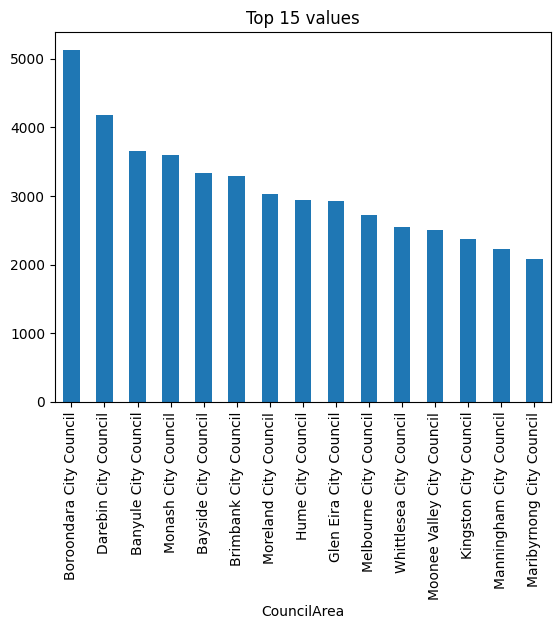

----------------------------------------


In [356]:
for col in cat_df.columns:
  print(f'{col} ')
  print()
  print('Number of uniuqe value ',cat_df[col].nunique())
  print('Top largest 30 value_Counts',cat_df[col].value_counts().nlargest(15))
  print('Rare value ',cat_df[col].value_counts().nsmallest(15))
  print()
  cat_df[col].value_counts().nlargest(15).plot(kind='bar')
  plt.title('Top 15 values')
  plt.show()
  print('-'*40)

Rooms
Number of unique value 14


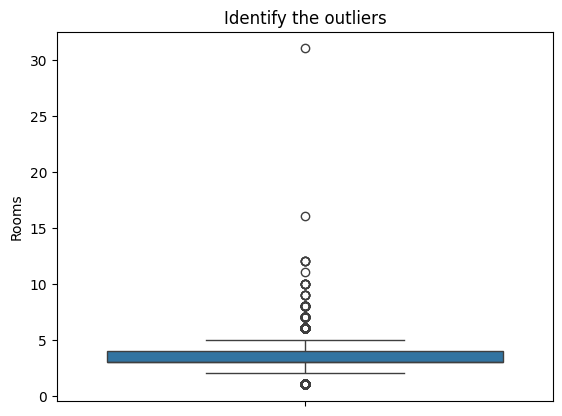

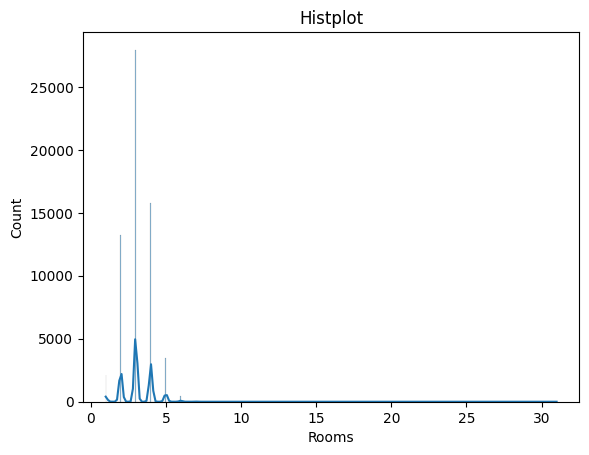


Postcode
Number of unique value 225


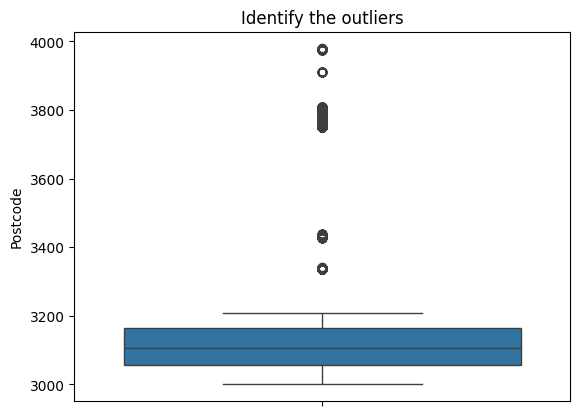

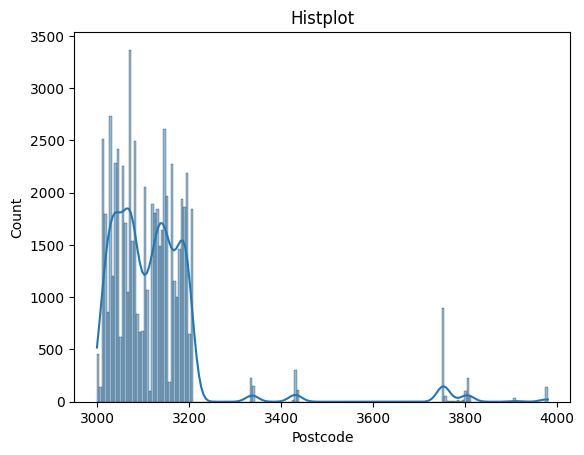


Propertycount
Number of unique value 368


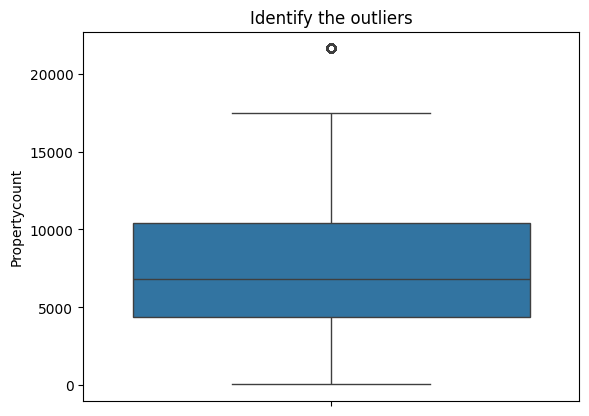

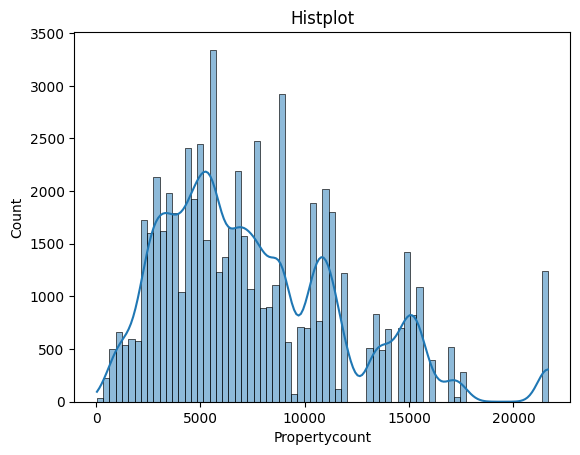


Distance
Number of unique value 180


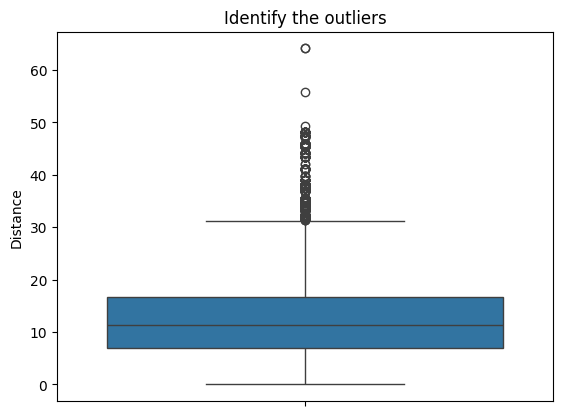

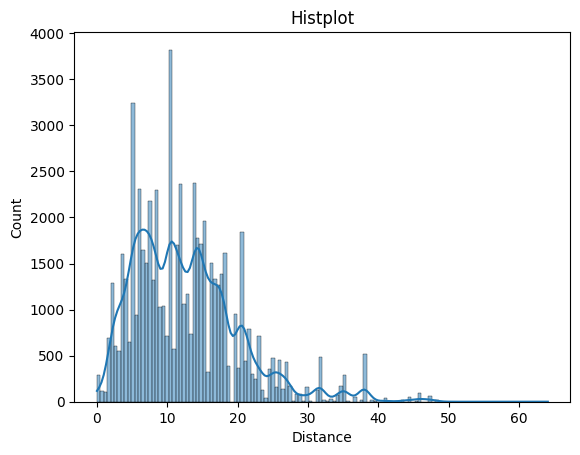

In [357]:
num_df.describe()
temp_num_df = num_df.drop(columns=['Price'])
for col in temp_num_df.columns:
  print(f'{col}')
  print('Number of unique value',temp_num_df[col].nunique())
  sns.boxplot(num_df[col])
  plt.title('Identify the outliers')

  plt.show()
  sns.histplot(num_df[col],kde=True)
  plt.title('Histplot')
  plt.show()
  print('')


In [358]:
right_skew=[]
left_skew=[]
for col in num_df.columns:
  if num_df[col].skew() >0:
    right_skew.append(col)
  else:
    left_skew.append(col)

In [262]:
right_skew

['Rooms', 'Price', 'Postcode', 'Propertycount', 'Distance']

# Bivariate analysis

In [359]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 63021 entries, 0 to 63022
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         63021 non-null  object        
 1   Address        63021 non-null  object        
 2   Rooms          63021 non-null  int64         
 3   Type           63021 non-null  object        
 4   Price          48432 non-null  float64       
 5   Method         63021 non-null  object        
 6   SellerG        63021 non-null  object        
 7   Date           63021 non-null  datetime64[ns]
 8   Postcode       63021 non-null  int64         
 9   Regionname     63021 non-null  object        
 10  Propertycount  63021 non-null  int64         
 11  Distance       63021 non-null  float64       
 12  CouncilArea    63021 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(7)
memory usage: 6.7+ MB


In [360]:
df['Method'].value_counts()

,count
Method,
S,34063
PI,9790
SP,8914
VB,5956
SN,2674
PN,651
W,484
SA,416
SS,73


<Axes: xlabel='Rooms', ylabel='Price'>

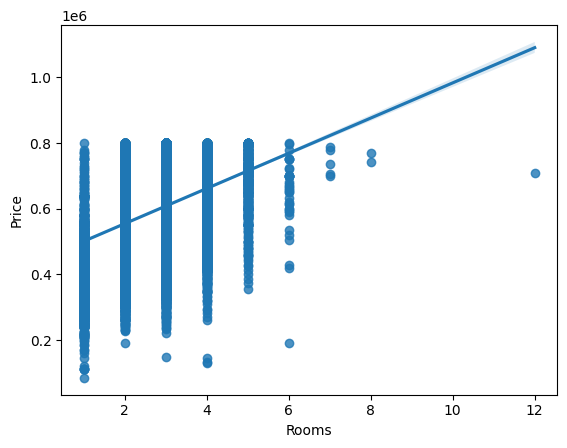

In [362]:
sns.regplot(data=df.dropna().loc[df.dropna()['Price'] <= 800000 , ['Price', 'Rooms']], y='Price', x='Rooms')

<Axes: xlabel='Rooms', ylabel='Price'>

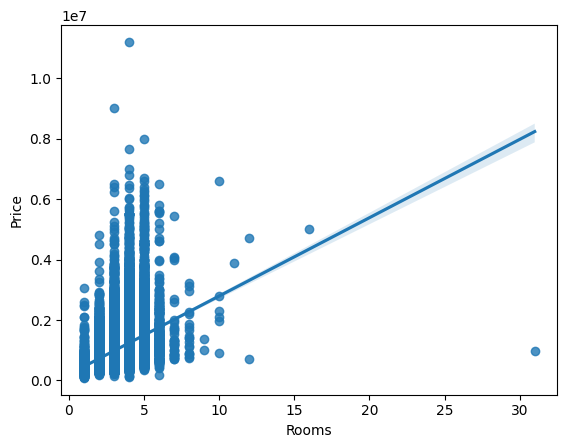

In [361]:
sns.regplot(data=df,x='Rooms',y='Price')

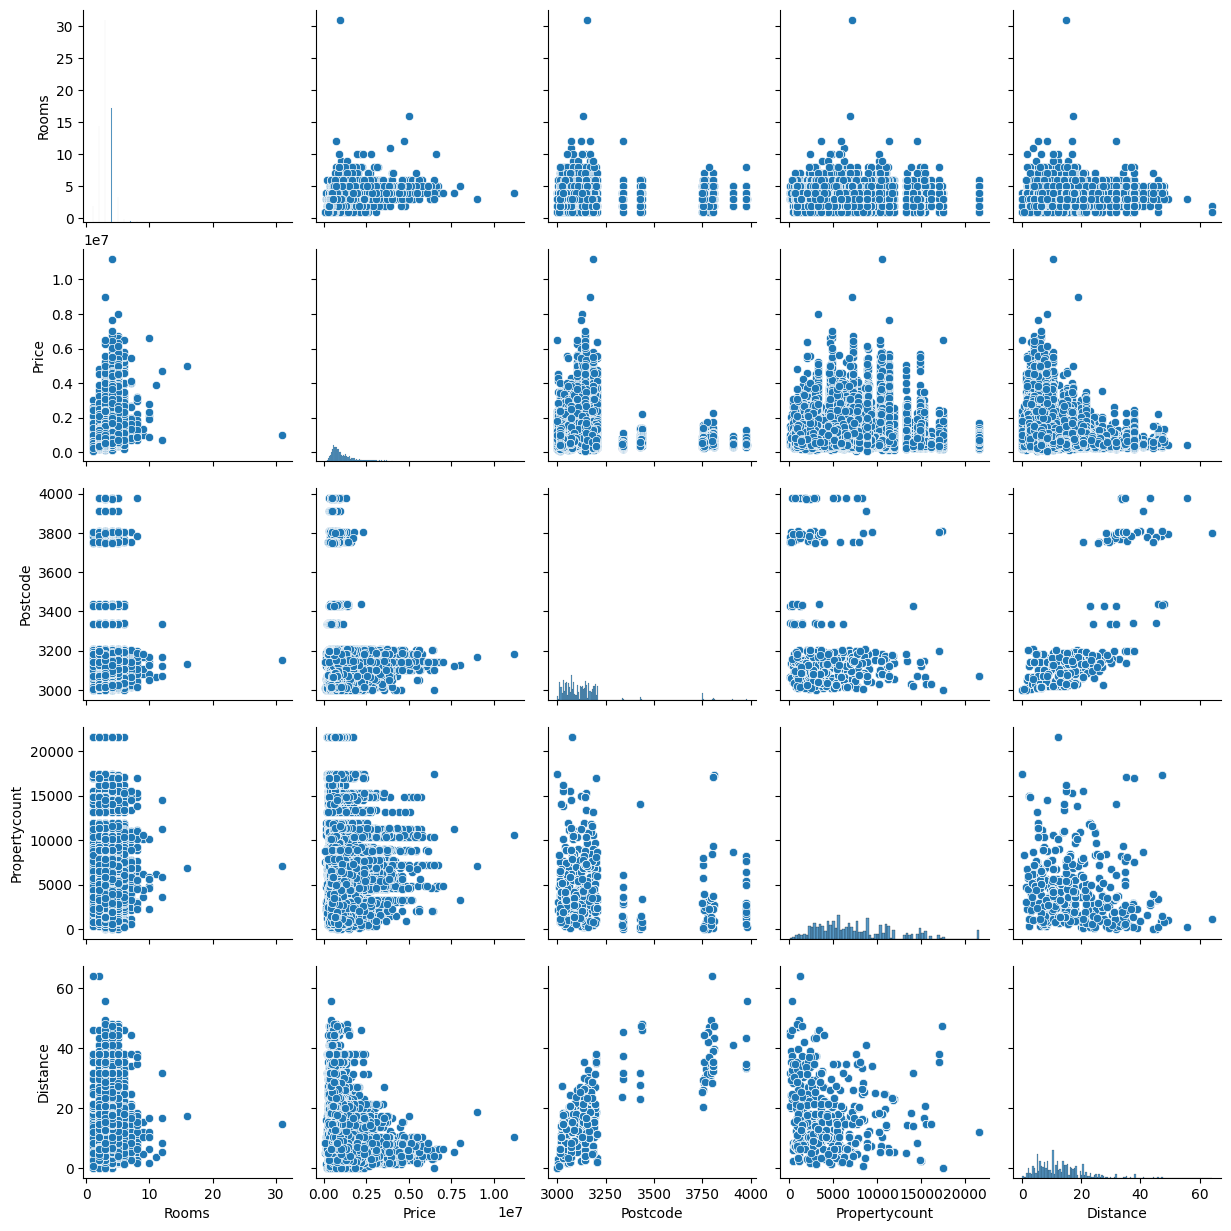

In [363]:
sns.pairplot(df)

In [364]:
data=df.drop(columns=['Address','Postcode'])

In [365]:
clean_df=data.dropna()
null_price_df=data[data['Price'].isnull()]

In [366]:
null_price_df

,Suburb,Rooms,Type,Price,Method,SellerG,Date,Regionname,Propertycount,Distance,CouncilArea
8,Albanvale,6,h,NaN,PI,hockingstuart,2017-04-01,Western Metropolitan,1899,14.0,Brimbank City Council
15,Altona Meadows,4,h,NaN,SN,Barry,2017-04-01,Western Metropolitan,7630,15.5,Hobsons Bay City Council
24,Ashburton,4,h,NaN,S,Jellis,2017-04-01,Southern Metropolitan,3052,10.2,Boroondara City Council
29,Attwood,4,h,NaN,SN,Barry,2017-04-01,Northern Metropolitan,1130,16.5,Hume City Council
38,Balwyn North,3,h,NaN,SP,Fletchers,2017-04-01,Southern Metropolitan,7809,9.7,Boroondara City Council
...,...,...,...,...,...,...,...,...,...,...,...
63001,Wyndham Vale,3,h,NaN,S,hockingstuart,2017-12-30,Western Metropolitan,5262,27.2,Wyndham City Council
63008,Yarraville,3,t,NaN,S,Jas,2017-12-30,Western Metropolitan,6543,6.3,Maribyrnong City Council
63010,Burwood,4,h,NaN,PN,@Realty,2018-03-31,Southern Metropolitan,5678,10.4,Monash City Council
63021,Thomastown,3,u,NaN,PI,Barry,2018-03-31,Northern Metropolitan,7955,15.3,Whittlesea City Council


In [367]:
clean_df

,Suburb,Rooms,Type,Price,Method,SellerG,Date,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,3,h,1490000.0,S,Jellis,2017-04-01,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,3,h,1220000.0,S,Marshall,2017-04-01,Northern Metropolitan,4019,3.0,Yarra City Council
2,Abbotsford,3,h,1420000.0,S,Nelson,2017-04-01,Northern Metropolitan,4019,3.0,Yarra City Council
3,Aberfeldie,3,h,1515000.0,S,Barry,2017-04-01,Western Metropolitan,1543,7.5,Moonee Valley City Council
4,Airport West,2,h,670000.0,S,Nelson,2017-04-01,Western Metropolitan,3464,10.4,Moonee Valley City Council
...,...,...,...,...,...,...,...,...,...,...,...
63016,Frankston,2,u,347700.0,SP,Aquire,2018-03-31,South-Eastern Metropolitan,17055,38.0,Frankston City Council
63017,Preston,3,h,808000.0,S,RW,2018-03-31,Northern Metropolitan,14577,8.4,Darebin City Council
63018,Roxburgh Park,3,h,566000.0,S,Raine,2018-03-31,Northern Metropolitan,5833,20.6,Hume City Council
63019,Roxburgh Park,3,h,500000.0,S,Raine,2018-03-31,Northern Metropolitan,5833,20.6,Hume City Council


In [368]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(clean_df.drop(columns='Price'),clean_df['Price'],test_size=.20,random_state=20)

In [369]:
x_train

,Suburb,Rooms,Type,Method,SellerG,Date,Regionname,Propertycount,Distance,CouncilArea
11636,Viewbank,4,h,S,Miles,2016-05-07,Eastern Metropolitan,2698,8.9,Banyule City Council
29170,Carnegie,2,t,S,Gary,2016-04-16,Southern Metropolitan,7822,10.1,Glen Eira City Council
46684,Sunbury,4,h,S,Brad,2017-12-23,Western Metropolitan,14092,31.7,Hume City Council
48437,Mickleham,4,h,S,Ray,2018-03-24,Northern Metropolitan,1158,20.6,Hume City Council
16626,Brunswick,3,h,VB,Nelson,2017-09-09,Northern Metropolitan,11918,5.2,Moreland City Council
...,...,...,...,...,...,...,...,...,...,...
41652,South Melbourne,4,h,S,hockingstuart,2017-10-21,Southern Metropolitan,5943,1.9,Port Phillip City Council
30580,Brunswick,1,u,S,Nelson,2017-09-16,Northern Metropolitan,11918,5.2,Moreland City Council
31028,Point Cook,2,h,S,hockingstuart,2017-09-16,Western Metropolitan,15542,14.7,Wyndham City Council
48420,Melton,3,h,S,Barry,2018-03-24,Western Victoria,3600,31.7,Melton City Council


In [370]:
x_train['Suburb'].value_counts().nlargest(25)

,count
Suburb,
Reservoir,860
Bentleigh East,551
Richmond,497
Preston,489
Craigieburn,486
Mount Waverley,448
Brunswick,424
Cheltenham,413
Northcote,408


In [371]:
top_25_suburbs = x_train['Suburb'].value_counts().nlargest(35).index

def reduce_suburbs(data, top_suburbs):

    data = data.copy()

    data['Suburb'] = data['Suburb'].apply(lambda x: x if x in top_suburbs else 'Other')
    return data

x_train = reduce_suburbs(x_train, top_25_suburbs)
x_test = reduce_suburbs(x_test, top_25_suburbs)

In [372]:
x_train.columns

Index(['Suburb', 'Rooms', 'Type', 'Method', 'SellerG', 'Date', 'Regionname',
       'Propertycount', 'Distance', 'CouncilArea'],
      dtype='object')

In [373]:
x_train['CouncilArea'].value_counts()

,count
CouncilArea,
Darebin City Council,2834
Boroondara City Council,2778
Banyule City Council,2311
Brimbank City Council,2148
Bayside City Council,2027
Moreland City Council,1986
Monash City Council,1960
Hume City Council,1911
Glen Eira City Council,1878


In [374]:
x_train['CouncilArea'].value_counts()

,count
CouncilArea,
Darebin City Council,2834
Boroondara City Council,2778
Banyule City Council,2311
Brimbank City Council,2148
Bayside City Council,2027
Moreland City Council,1986
Monash City Council,1960
Hume City Council,1911
Glen Eira City Council,1878


In [375]:
from feature_engine.encoding import RareLabelEncoder

In [376]:
rare_encoder = RareLabelEncoder(

    n_categories=10,
    replace_with='Other'
)


x_train['CouncilArea'] = rare_encoder.fit_transform(x_train[['CouncilArea']])
x_test['CouncilArea'] = rare_encoder.transform(x_test[['CouncilArea']])

/usr/local/lib/python3.13/dist-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)


In [378]:
x_train['CouncilArea'].value_counts()

,count
CouncilArea,
Other,22701
Darebin City Council,2834
Boroondara City Council,2778
Banyule City Council,2311
Brimbank City Council,2148
Bayside City Council,2027
Moreland City Council,1986
Monash City Council,1960


In [377]:
x_train['Rooms'].value_counts()

,count
Rooms,
3,17430
4,9275
2,8552
5,1888
1,1331
6,223
7,22
8,14
10,5


In [379]:
def categorize_room(Rooms):
    if Rooms == 1:
        return 'Single / Couple'
    elif 2 <= Rooms <= 3:
        return 'Small Family'
    elif Rooms > 3 and Rooms <= 5:
        return 'Medium Family'
    elif Rooms > 5 and Rooms <= 7:
        return 'Large Family'
    elif Rooms > 7:
        return 'Joint Family'
    else:
        return 'Other'



In [380]:
x_train['Room_Category'] = x_train['Rooms'].apply(categorize_room)
x_test['Room_Category'] = x_test['Rooms'].apply(categorize_room)

In [383]:
x_train['SellerG'].value_counts().nlargest(10)

,count
SellerG,
Barry,3880
Jellis,3253
Nelson,3224
Ray,2903
hockingstuart,2749
Buxton,2089
Marshall,1394
Fletchers,962
Biggin,816


In [384]:
rare_encoder = RareLabelEncoder(

    n_categories=10,
    replace_with='Other'
)


x_train['SellerG'] = rare_encoder.fit_transform(x_train[['SellerG']])
x_test['SellerG'] = rare_encoder.transform(x_test[['SellerG']])

/usr/local/lib/python3.13/dist-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)


In [388]:
x_train['Regionname'].value_counts()

,count
Regionname,
Northern Metropolitan,10890
Southern Metropolitan,10049
Western Metropolitan,7673
Eastern Metropolitan,6139
South-Eastern Metropolitan,3198
Other,796


In [387]:
rare_encoder = RareLabelEncoder(

    n_categories=5,
    replace_with='Other'
)

x_train['Regionname'] = rare_encoder.fit_transform(x_train[['Regionname']])
x_test['Regionname'] = rare_encoder.transform(x_test[['Regionname']])

/usr/local/lib/python3.13/dist-packages/feature_engine/variable_handling/_variable_type_checks.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  var = pd.to_datetime(column, utc=True)


In [389]:
x_train

,Suburb,Rooms,Type,Method,SellerG,Date,Regionname,Propertycount,Distance,CouncilArea,Room_Category
11636,Other,4,h,S,Other,2016-05-07,Eastern Metropolitan,2698,8.9,Banyule City Council,Medium Family
29170,Other,2,t,S,Other,2016-04-16,Southern Metropolitan,7822,10.1,Other,Small Family
46684,Other,4,h,S,Other,2017-12-23,Western Metropolitan,14092,31.7,Other,Medium Family
48437,Other,4,h,S,Ray,2018-03-24,Northern Metropolitan,1158,20.6,Other,Medium Family
16626,Brunswick,3,h,VB,Nelson,2017-09-09,Northern Metropolitan,11918,5.2,Moreland City Council,Small Family
...,...,...,...,...,...,...,...,...,...,...,...
41652,Other,4,h,S,hockingstuart,2017-10-21,Southern Metropolitan,5943,1.9,Other,Medium Family
30580,Brunswick,1,u,S,Nelson,2017-09-16,Northern Metropolitan,11918,5.2,Moreland City Council,Single / Couple
31028,Other,2,h,S,hockingstuart,2017-09-16,Western Metropolitan,15542,14.7,Other,Small Family
48420,Other,3,h,S,Barry,2018-03-24,Other,3600,31.7,Other,Small Family


<Axes: xlabel='Propertycount', ylabel='Count'>

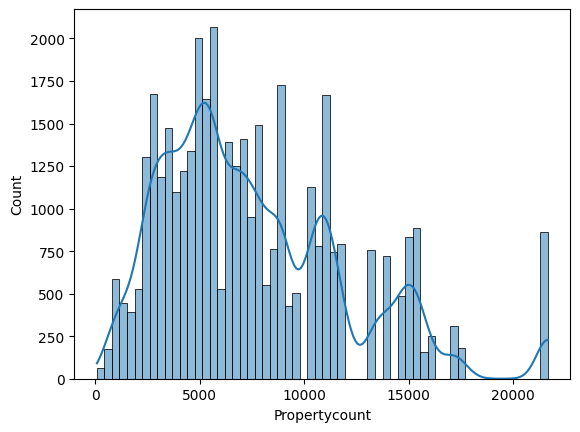

In [303]:
sns.histplot(x_train['Propertycount'],kde=True)

In [306]:
x_train['Distance'].value_counts()

,count
Distance,
10.5,927
13.8,881
8.4,863
12.0,860
6.2,773
...,...
33.0,1
49.3,1
30.6,1


In [321]:
x_train

,Suburb,Rooms,Type,Method,SellerG,Date,Regionname,Propertycount,Distance,CouncilArea,Room_Category
11636,Other,4,h,S,Miles,2016-05-07,Eastern Metropolitan,2698,8.9,Banyule City Council,Medium Family
29170,Other,2,t,S,Gary,2016-04-16,Southern Metropolitan,7822,10.1,Other,Small Family
48437,Other,4,h,S,Ray,2018-03-24,Northern Metropolitan,1158,20.6,Other,Medium Family
16626,Brunswick,3,h,VB,Nelson,2017-09-09,Northern Metropolitan,11918,5.2,Moreland City Council,Small Family
671,Other,3,h,SP,Raine,2017-07-01,Western Metropolitan,3464,10.4,Other,Small Family
...,...,...,...,...,...,...,...,...,...,...,...
61842,Coburg,3,h,PI,Ray,2016-07-30,Northern Metropolitan,11204,6.7,Darebin City Council,Small Family
41652,Other,4,h,S,hockingstuart,2017-10-21,Southern Metropolitan,5943,1.9,Other,Medium Family
30580,Brunswick,1,u,S,Nelson,2017-09-16,Northern Metropolitan,11918,5.2,Moreland City Council,Single / Couple
31028,Other,2,h,S,hockingstuart,2017-09-16,Western Metropolitan,15542,14.7,Other,Small Family


In [391]:

Q1 = x_train['Propertycount'].quantile(0.25)
Q3 = x_train['Propertycount'].quantile(0.85)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

train_mask = (x_train['Propertycount'] >= lower_bound) & (x_train['Propertycount'] <= upper_bound)
x_train = x_train[train_mask]
y_train = y_train[train_mask]

x_test['Propertycount'] = x_test['Propertycount'].clip(lower=lower_bound, upper=upper_bound)

<Axes: xlabel='Propertycount', ylabel='Count'>

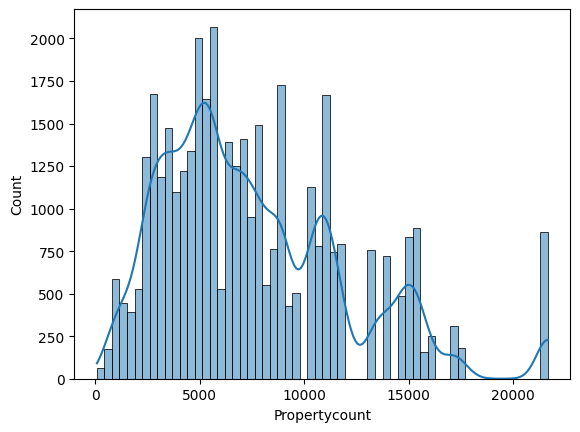

In [392]:
sns.histplot(x_train['Propertycount'],kde=True)

<Axes: ylabel='Distance'>

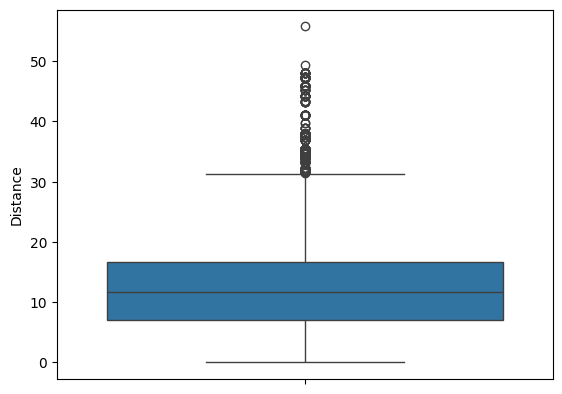

In [395]:
sns.boxplot(x_train['Distance'])

In [399]:
Q1 = x_train['Distance'].quantile(0.25)
Q3 = x_train['Distance'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

train_mask = (x_train['Distance'] >= lower_bound) & (x_train['Distance'] <= upper_bound)
x_train = x_train[train_mask]
y_train = y_train[train_mask]

x_test['Distance'] = x_test['Distance'].clip(lower=lower_bound, upper=upper_bound)

<Axes: ylabel='Distance'>

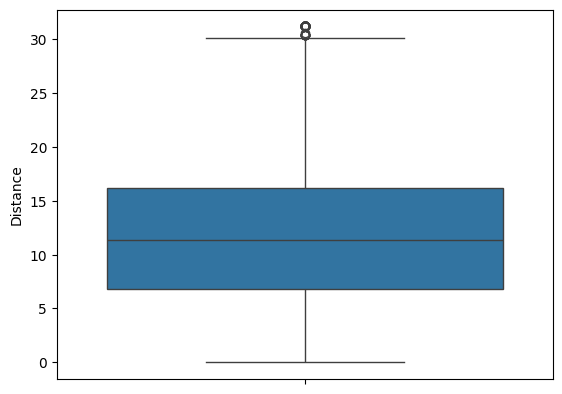

In [402]:
sns.boxplot(x_train['Distance'])

In [403]:
from sklearn.compose import ColumnTransformer

In [404]:
skewed_cols = ['Distance', 'Propertycount']

for col in skewed_cols:
    x_train[col] = np.log1p(x_train[col])
    x_test[col] = np.log1p(x_test[col])

/tmp/ipykernel_1034/1215815913.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train[col] = np.log1p(x_train[col])


<Axes: xlabel='Distance', ylabel='Count'>

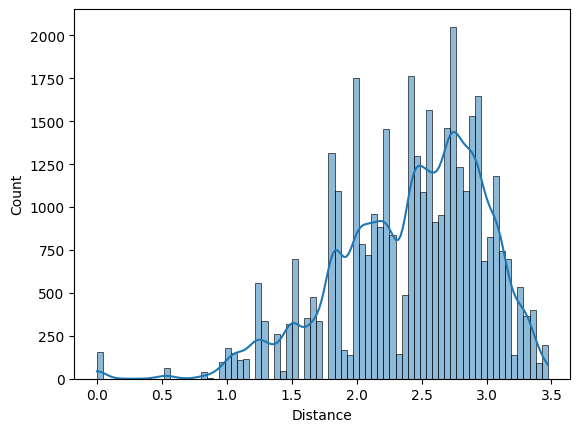

In [405]:
sns.histplot(x_train['Distance'],kde=True)

In [407]:
x_train.drop(columns=['Rooms','Date'],inplace=True)

/tmp/ipykernel_1034/144742806.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train.drop(columns=['Rooms','Date'],inplace=True)


In [408]:
x_test.drop(columns=['Rooms','Date'],inplace=True)

KeyError: "['Rooms', 'Date'] not found in axis"

In [409]:
x_train

,Suburb,Type,Method,SellerG,Regionname,Propertycount,Distance,CouncilArea,Room_Category
11636,Other,h,S,Other,Eastern Metropolitan,7.900637,2.292535,Banyule City Council,Medium Family
29170,Other,t,S,Other,Southern Metropolitan,8.964823,2.406945,Other,Small Family
48437,Other,h,S,Ray,Northern Metropolitan,7.055313,3.072693,Other,Medium Family
16626,Brunswick,h,VB,Nelson,Northern Metropolitan,9.385889,1.824549,Moreland City Council,Small Family
671,Other,h,SP,Other,Western Metropolitan,8.150468,2.433613,Other,Small Family
...,...,...,...,...,...,...,...,...,...
61842,Coburg,h,PI,Ray,Northern Metropolitan,9.324115,2.041220,Darebin City Council,Small Family
41652,Other,h,S,hockingstuart,Southern Metropolitan,8.690138,1.064711,Other,Medium Family
30580,Brunswick,u,S,Nelson,Northern Metropolitan,9.385889,1.824549,Moreland City Council,Single / Couple
31028,Other,h,S,hockingstuart,Western Metropolitan,9.651366,2.753661,Other,Small Family


In [410]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ['Distance', 'Propertycount']

categorical_features = ['Suburb', 'Type','Method','SellerG','CouncilArea', 'Regionname']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

In [412]:
x_test_processed

array([[1.2793369009462985, -0.6939869594123486, 0.0, ..., 0.0, 0.0,
        'Small Family'],
       [1.144353187109813, 0.38142069870602163, 0.0, ..., 0.0, 0.0,
        'Medium Family'],
       [1.1360837880097119, -0.3723462048426326, 0.0, ..., 0.0, 0.0,
        'Small Family'],
       ...,
       [-2.1269947009654184, 1.3419606357226501, 0.0, ..., 0.0, 0.0,
        'Small Family'],
       [-1.9770082524943589, 1.3356146531795257, 0.0, ..., 1.0, 0.0,
        'Small Family'],
       [0.16814030811846023, -0.8411174890561973, 0.0, ..., 1.0, 0.0,
        'Small Family']], dtype=object)

In [413]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

x_train_df = pd.DataFrame(
    x_train_processed,
    columns=feature_names,
    index=x_train.index
)


x_test_df = pd.DataFrame(
    x_test_processed,
    columns=feature_names,
    index=x_test.index
)

x_train_df.head()

      num__Distance num__Propertycount cat__Suburb_Balwyn North  \
11636     -0.231248          -1.272047                      0.0   
29170     -0.028309           0.352993                      0.0   
48437      1.152584          -2.562878                      0.0   
16626     -1.061352           0.995971                      0.0   
671        0.018995          -0.890549                      0.0   

      cat__Suburb_Bentleigh cat__Suburb_Bentleigh East cat__Suburb_Brighton  \
11636                   0.0                        0.0                  0.0   
29170                   0.0                        0.0                  0.0   
48437                   0.0                        0.0                  0.0   
16626                   0.0                        0.0                  0.0   
671                     0.0                        0.0                  0.0   

      cat__Suburb_Brighton East cat__Suburb_Brunswick cat__Suburb_Bundoora  \
11636                       0.0             

In [419]:
x_train_df['remainder__Room_Category'].value_counts()

,count
remainder__Room_Category,
Small Family,25241
Medium Family,10693
Single / Couple,1325
Large Family,236
Joint Family,23


In [420]:
from sklearn.preprocessing import OrdinalEncoder

room_order = [['Single / Couple', 'Small Family', 'Medium Family', 'Large Family', 'Joint Family']]
ordinal_encoder = OrdinalEncoder(
    categories=room_order,
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

x_train_df['remainder__Room_Category'] = ordinal_encoder.fit_transform(x_train_df[['remainder__Room_Category']])
x_test_df['remainder__Room_Category'] = ordinal_encoder.transform(x_test_df[['remainder__Room_Category']])

In [421]:
x_test_df

,num__Distance,num__Propertycount,cat__Suburb_Balwyn North,cat__Suburb_Bentleigh,cat__Suburb_Bentleigh East,cat__Suburb_Brighton,cat__Suburb_Brighton East,cat__Suburb_Brunswick,cat__Suburb_Bundoora,cat__Suburb_Camberwell,...,cat__CouncilArea_Monash City Council,cat__CouncilArea_Moreland City Council,cat__CouncilArea_Other,cat__Regionname_Eastern Metropolitan,cat__Regionname_Northern Metropolitan,cat__Regionname_Other,cat__Regionname_South-Eastern Metropolitan,cat__Regionname_Southern Metropolitan,cat__Regionname_Western Metropolitan,remainder__Room_Category
43869,1.279337,-0.693987,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
46657,1.144353,0.381421,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0
9833,1.136084,-0.372346,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
40173,0.962044,0.752293,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0
57065,-2.126995,1.341961,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28997,-1.407788,0.230082,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0
29233,-0.565429,-0.361711,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
48633,-2.126995,1.341961,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
50040,-1.977008,1.335615,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


In [422]:
from sklearn.preprocessing import StandardScaler

price_scaler = StandardScaler()

y_train_scaled = price_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

y_test_scaled = price_scaler.transform(y_test.values.reshape(-1, 1)).ravel()

In [425]:
y_test_scaled.shape

(9687,)

In [426]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_df[['num__Distance', 'num__Propertycount']] = scaler.fit_transform(x_train_df[['num__Distance', 'num__Propertycount']])

x_test_df[['num__Distance', 'num__Propertycount']] = scaler.transform(x_test_df[['num__Distance', 'num__Propertycount']])

In [427]:
x_train_df

,num__Distance,num__Propertycount,cat__Suburb_Balwyn North,cat__Suburb_Bentleigh,cat__Suburb_Bentleigh East,cat__Suburb_Brighton,cat__Suburb_Brighton East,cat__Suburb_Brunswick,cat__Suburb_Bundoora,cat__Suburb_Camberwell,...,cat__CouncilArea_Monash City Council,cat__CouncilArea_Moreland City Council,cat__CouncilArea_Other,cat__Regionname_Eastern Metropolitan,cat__Regionname_Northern Metropolitan,cat__Regionname_Other,cat__Regionname_South-Eastern Metropolitan,cat__Regionname_Southern Metropolitan,cat__Regionname_Western Metropolitan,remainder__Room_Category
11636,-0.231248,-1.272047,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0
29170,-0.028309,0.352993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
48437,1.152584,-2.562878,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0
16626,-1.061352,0.995971,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
671,0.018995,-0.890549,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61842,-0.677025,0.901641,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
41652,-2.409141,-0.066459,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0
30580,-1.061352,0.995971,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
31028,0.586690,1.401361,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0


In [442]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_model = LinearRegression()


baseline_model.fit(x_train_df, y_train_scaled)

y_pred = baseline_model.predict(x_test_df)


mae = mean_absolute_error(y_test_scaled, y_pred)
mse = mean_squared_error(y_test_scaled, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_scaled, y_pred)

print("--- Baseline Linear Regression Performance ---")
print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"R2 Score (Accuracy): {r2:.4f}")

--- Baseline Linear Regression Performance ---
MAE (Mean Absolute Error): 0.43
RMSE (Root Mean Squared Error): 0.67
R2 Score (Accuracy): 0.5471


In [444]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_model = DecisionTreeRegressor()


tree_model.fit(x_train_df, y_train_scaled)


y_pred = tree_model.predict(x_test_df)


mae = mean_absolute_error(y_test_scaled, y_pred)
mse = mean_squared_error(y_test_scaled, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_scaled, y_pred)

print("--- Baseline Linear Regression Performance ---")
print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"R2 Score (Accuracy): {r2:.4f}")

--- Baseline Linear Regression Performance ---
MAE (Mean Absolute Error): 0.35
RMSE (Root Mean Squared Error): 0.62
R2 Score (Accuracy): 0.6136


In [445]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


baseline_model = RandomForestRegressor(n_estimators=100, random_state=42)



baseline_model.fit(x_train_df, y_train_scaled)


y_pred = baseline_model.predict(x_test_df)

mae = mean_absolute_error(y_test_scaled, y_pred)
mse = mean_squared_error(y_test_scaled, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_scaled, y_pred)

print("--- Baseline Linear Regression Performance ---")
print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"R2 Score (Accuracy): {r2:.4f}")

--- Baseline Linear Regression Performance ---
MAE (Mean Absolute Error): 0.34
RMSE (Root Mean Squared Error): 0.59
R2 Score (Accuracy): 0.6476


In [447]:
import xgboost as xgb


x_train_df_num = x_train_df.astype(float)
x_test_df_num = x_test_df.astype(float)


xgb_tuned = xgb.XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(x_train_df_num, y_train_scaled)


y_pred_xgb = xgb_model.predict(x_test_df_num)


mae_xgb = mean_absolute_error(y_test_scaled, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test_scaled, y_pred_xgb))
r2_xgb = r2_score(y_test_scaled, y_pred_xgb)

print("--- XGBoost Model Performance ---")
print(f"MAE: {mae_xgb:.2f}")
print(f"RMSE: {rmse_xgb:.2f}")
print(f"R2 Score (Accuracy): {r2_xgb:.4f}")

--- XGBoost Model Performance ---
MAE: 0.32
RMSE: 0.56
R2 Score (Accuracy): 0.6768


In [450]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

x_train_df_num = x_train_df.astype(float)
x_test_df_num = x_test_df.astype(float)

xgb_base = xgb.XGBRegressor(random_state=42)

param_distributions = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 7, 10],
    'learning_rate': [0.01, 0.03, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=25,
    scoring='r2',
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(x_train_df_num, y_train_scaled)

print("--- Best Hyperparameters Found ---")
print(random_search.best_params_)

best_xgb_model = random_search.best_estimator_
y_pred_tuned = best_xgb_model.predict(x_test_df_num)

r2_tuned = r2_score(y_test_scaled, y_pred_tuned)
mae_tuned = mean_absolute_error(y_test_scaled, y_pred_tuned)
rmse_tuned = np.sqrt(mean_squared_error(y_test_scaled, y_pred_tuned))

print("\n--- Tuned XGBoost Performance ---")
print(f"MAE: {mae_tuned:.2f}")
print(f"RMSE: {rmse_tuned:.2f}")
print(f"R2 Score (Accuracy): {r2_tuned:.4f}")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
--- Best Hyperparameters Found ---
{'subsample': 1.0, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 0.6}

--- Tuned XGBoost Performance ---
MAE: 0.32
RMSE: 0.56
R2 Score (Accuracy): 0.6781


In [452]:
x_train_df_num = x_train_df.astype(float)
x_test_df_num = x_test_df.astype(float)


xgb_tuned = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.2,
    max_depth=7,
    subsample=1.0,
    colsample_bytree=0.6,
    random_state=42
)

xgb_model.fit(x_train_df_num, y_train_scaled)


y_pred_xgb = xgb_model.predict(x_test_df_num)


mae_xgb = mean_absolute_error(y_test_scaled, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test_scaled, y_pred_xgb))
r2_xgb = r2_score(y_test_scaled, y_pred_xgb)

print("--- XGBoost Model Best Performance ---")
print(f"MAE: {mae_xgb:.2f}")
print(f"RMSE: {rmse_xgb:.2f}")
print(f"R2 Score (Accuracy): {r2_xgb:.4f}")

--- XGBoost Model Best Performance ---
MAE: 0.32
RMSE: 0.56
R2 Score (Accuracy): 0.6768


In [453]:
pip install optuna


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [458]:
from sklearn.metrics import r2_score
import xgboost as xgb

x_train_df_num = x_train_df.astype(float)
x_test_df_num = x_test_df.astype(float)

xgb_tuned = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.2,
    max_depth=7,
    subsample=1.0,
    colsample_bytree=0.6,
    random_state=42
)

xgb_tuned.fit(x_train_df_num, y_train_scaled)

# 2. Train data prediction
y_train_pred = xgb_tuned.predict(x_train_df_num)
train_r2 = r2_score(y_train_scaled, y_train_pred)

# 3. Test data prediction
y_test_pred = xgb_tuned.predict(x_test_df_num)
test_r2 = r2_score(y_test_scaled, y_test_pred)

print(f"Train R2 Score: {train_r2:.4f}")
print(f"Test R2 Score: {test_r2:.4f}")

Train R2 Score: 0.7605
Test R2 Score: 0.6795


In [460]:
import optuna
import xgboost as xgb
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

def objective(trial):

    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 5),
        'random_state': 42,
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**param)

    scores = cross_val_score(model, x_train_df_num, y_train_scaled, cv=5, scoring='r2', n_jobs=-1)


    return scores.mean()

study = optuna.create_study(direction='maximize')

study.optimize(objective, n_trials=30)

print("--- Best Hyperparameters Found ---")
print(study.best_params)
print(f"\nBest Cross-Validation R2 Score: {study.best_value:.4f}")

best_params = study.best_params.copy()
best_params['random_state'] = 42

final_xgb_model = xgb.XGBRegressor(**best_params)
final_xgb_model.fit(x_train_df_num, y_train_scaled)
y_pred_optuna = final_xgb_model.predict(x_test_df_num)
final_r2 = r2_score(y_test_scaled, y_pred_optuna)
print(f"Final Test R2 Score with Optuna: {final_r2:.4f}")

[I 2026-10-30 10:19:31,983] A new study created in memory with name: no-name-4d898609-aefc-4937-aadd-d8214db221c1
[I 2026-10-30 10:19:37,752] Trial 0 finished with value: 0.6959609005414782 and parameters: {'n_estimators': 190, 'max_depth': 5, 'learning_rate': 0.031051184803312124, 'subsample': 0.6282706591846615, 'colsample_bytree': 0.8829492659236378, 'min_child_weight': 3}. Best is trial 0 with value: 0.6959609005414782.
[I 2026-10-30 10:19:48,664] Trial 1 finished with value: 0.7097441749130657 and parameters: {'n_estimators': 282, 'max_depth': 6, 'learning_rate': 0.027054088599919965, 'subsample': 0.9660957925695233, 'colsample_bytree': 0.9720146138037721, 'min_child_weight': 1}. Best is trial 1 with value: 0.7097441749130657.
[I 2026-10-30 10:19:54,602] Trial 2 finished with value: 0.7139007233018899 and parameters: {'n_estimators': 192, 'max_depth': 7, 'learning_rate': 0.11641302712101702, 'subsample': 0.9330730930238376, 'colsample_bytree': 0.7768375655570263, 'min_child_weight

--- Best Hyperparameters Found ---
{'n_estimators': 140, 'max_depth': 8, 'learning_rate': 0.06461464695507668, 'subsample': 0.98549534441254, 'colsample_bytree': 0.7242356793022512, 'min_child_weight': 2}

Best Cross-Validation R2 Score: 0.7163
Final Test R2 Score with Optuna: 0.6804


In [470]:
import pandas as pd
import numpy as np

new_house_raw = pd.DataFrame({
    'Suburb': ['Richmond'],
    'Type': ['h'],
    'Method': ['S'],
    'SellerG': ['Jellis'],
    'Regionname': ['Southern Metropolitan'],
    'Distance': [2.5],
    'Propertycount': [4019],
    'CouncilArea': ['Yarra City Council'],
    'Room_Category': ['Small Family']
})

new_house_raw['Distance'] = np.log1p(new_house_raw['Distance'])
new_house_raw['Propertycount'] = np.log1p(new_house_raw['Propertycount'])

new_house_processed = preprocessor.transform(new_house_raw)


new_house_df = pd.DataFrame(
    new_house_processed,
    columns=preprocessor.get_feature_names_out(),
    index=[0]
)

new_house_df['remainder__Room_Category'] = ordinal_encoder.transform(new_house_df[['remainder__Room_Category']])

predicted_scaled_price = tree_model.predict(new_house_df)
predicted_price = price_scaler.inverse_transform(predicted_scaled_price.reshape(-1, 1)).ravel()

print(f"Predicted House Price: ${predicted_price[0]:,.2f}")

Predicted House Price: $1,469,000.00


In [469]:
df[(df['Type']=='h') & (df['Method']=='S') & (df['Regionname'] =='Southern Metropolitan')]

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
9,Albert Park,18 Mills St,3,h,1925000.0,S,Cayzer,2017-04-01,3206,Southern Metropolitan,3280,3.0,Port Phillip City Council
18,Armadale,6A Auburn Gr,2,h,2110000.0,S,Jellis,2017-04-01,3143,Southern Metropolitan,4836,6.3,Stonnington City Council
19,Armadale,746 High St,3,h,1386000.0,S,Marshall,2017-04-01,3143,Southern Metropolitan,4836,6.3,Stonnington City Council
24,Ashburton,1 Pitt St,4,h,NaN,S,Jellis,2017-04-01,3147,Southern Metropolitan,3052,10.2,Boroondara City Council
26,Ashwood,43 Douglas St,4,h,1435000.0,S,Ray,2017-04-01,3147,Southern Metropolitan,2894,10.2,Monash City Council
...,...,...,...,...,...,...,...,...,...,...,...,...,...
62757,Murrumbeena,5 Packer St,3,h,1590000.0,S,Jellis,2017-12-30,3163,Southern Metropolitan,4442,10.1,Glen Eira City Council
62805,Prahran,61 Chomley St,3,h,NaN,S,hockingstuart,2017-12-30,3181,Southern Metropolitan,7717,4.6,Stonnington City Council
62859,Ripponlea,23 Erindale Av,2,h,1380000.0,S,Cayzer,2017-12-30,3185,Southern Metropolitan,821,7.2,Port Phillip City Council
62871,Sandringham,29 Victoria St,4,h,NaN,S,hockingstuart,2017-12-30,3191,Southern Metropolitan,4497,15.2,Bayside City Council
